# Assignment 3: Bagging and random forests for attack prediction (UNSW-NB15)

Same data, split and pre-processing as Assignment 2, so the results can be compared directly with the A2 k-NN and decision tree.

**What is in here**
1. Data and pre-processing (copied from A2)
2. The two A2 models again (k-NN and decision tree) as baselines
3. Bagging written from scratch, applied to the decision tree and to k-NN
4. A random forest from scikit-learn (with a small check of `max_features`)
5. Results: metrics, per-class results, confusion matrices, effect of the number of models, false alarms, bootstrap comparisons
6. A quick try at class re-weighting

**Running it:** the slow parts are the k-NN predictions (the single k-NN and the bagged k-NN). Set `QUICK = True` first to check that everything runs on a small sample.

In [183]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score, accuracy_score
from sklearn.feature_selection import f_classif

sklearn.set_config(working_memory=128)   # keeps the k-NN distance blocks small so the laptop does not run out of memory
sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# ---------------- settings ----------------
SEED = 27                # run the whole notebook once with SEED = 1 and once with SEED = 2 (the last cell averages the saved results)
SEEDS_TO_AVERAGE = [19, 27]
SPLIT_SEED = SEED       # the seed also decides the train/test split; set to 42 to keep the A2 split and vary only the models
TAG = f"seed{SEED}"    # prefix for the saved files
QUICK = False          # True = use only 20,000 rows to check that the notebook runs
N_TREES = 200          # number of trees for bagged trees and the random forest
N_KNN_BAGS = 10        # number of k-NN models in the bagged k-NN
KNN_BAG_FRAC = 0.3     # each k-NN bag is a bootstrap sample of this fraction of the training data (keeps the cost down)

# best settings found in Assignment 2
KNN_PARAMS = dict(n_neighbors=9, weights="distance", metric="cosine")
TREE_PARAMS = dict(criterion="entropy", max_depth=15, min_samples_leaf=1, class_weight="balanced")

class_mapping = {0: "Normal", 1: "Reconnaissance", 2: "Backdoor", 3: "DoS", 4: "Exploits",
                 5: "Analysis", 6: "Fuzzers", 7: "Worms", 8: "Shellcode", 9: "Generic"}

## 1. Data and pre-processing (as in Assignment 2)

In [185]:
df = pd.read_csv("networkTraffic.csv", na_values="?")
if QUICK:
    df = df.sample(20000, random_state=SEED)
print("Shape:", df.shape)

target_col = df.columns[-1]
X = df.drop(columns=[target_col, "id"]) if "id" in df.columns else df.drop(columns=[target_col])
y = df[target_col]
mask = y.notna()
X, y = X[mask], y[mask]

categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
print("Categorical:", categorical_cols)
print("Numeric:", len(numeric_cols), "columns")

# same kind of split as A2 (stratified 80/20); A2 used seed 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SPLIT_SEED)
print(X_train.shape, X_test.shape)

Shape: (257673, 44)
Categorical: ['proto', 'service', 'state']
Numeric: 39 columns
(206138, 42) (51535, 42)


In [186]:
# Drop highly correlated numeric features (same method as A2): for each correlated pair keep the
# feature with the higher ANOVA F-score. Everything is calculated on the training data only.
CORR_THRESHOLD = 0.99
X_train_filled = X_train[numeric_cols].fillna(X_train[numeric_cols].median())
f_scores, _ = f_classif(X_train_filled, y_train)
target_relevance = pd.Series(f_scores, index=numeric_cols)

corr_matrix = X_train[numeric_cols].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = set()
for col in upper.columns:
    for other in upper.index[upper[col] > CORR_THRESHOLD].tolist():
        loser = other if target_relevance[col] >= target_relevance[other] else col
        to_drop.add(loser)
to_drop = list(to_drop)
print(f"Dropping {len(to_drop)} correlated columns:", to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
numeric_cols = [c for c in numeric_cols if c not in to_drop]

Dropping 3 correlated columns: ['sbytes', 'ct_ftp_cmd', 'dbytes']


In [187]:
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_bounds_ = X.quantile(self.lower)
        self.upper_bounds_ = X.quantile(self.upper)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        return X.clip(lower=self.lower_bounds_, upper=self.upper_bounds_, axis=1).values


# k-NN needs scaled features (it works with distances)
knn_preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("cap", OutlierCapper()),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
], sparse_threshold=0)   # sparse_threshold=0 just keeps the output as a normal array, which is easy to index

# trees do not need scaling or outlier capping
tree_preprocessor = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
], sparse_threshold=0)

# Pre-process once (fitted on the training data only). Every model below uses these arrays.
Xk_train = knn_preprocessor.fit_transform(X_train)
Xk_test = knn_preprocessor.transform(X_test)
Xt_train = tree_preprocessor.fit_transform(X_train)
Xt_test = tree_preprocessor.transform(X_test)

y_tr = y_train.values
y_te = y_test.values
classes = np.sort(np.unique(y_tr))
print("k-NN features:", Xk_train.shape[1], "| tree features:", Xt_train.shape[1])

k-NN features: 191 | tree features: 191


## 2. Helpers for evaluation

Macro-F1 is the main metric (as in A2). The extra helper reports the **detection rate** (share of attacks flagged as some attack) and the **false-alarm rate** (share of normal traffic flagged as an attack).

In [189]:
all_preds = {}      # model name -> test predictions
rows = []           # one row of metrics per model

def evaluate(name, preds, fit_seconds=np.nan, predict_seconds=np.nan):
    all_preds[name] = preds
    attack = y_te != 0           # class 0 = Normal
    flagged = preds != 0
    rows.append({
        "model": name,
        "macro_f1": f1_score(y_te, preds, average="macro"),
        "weighted_f1": f1_score(y_te, preds, average="weighted"),
        "accuracy": accuracy_score(y_te, preds),
        "balanced_accuracy": balanced_accuracy_score(y_te, preds),
        "detection_rate": flagged[attack].mean(),
        "false_alarm_rate": flagged[~attack].mean(),
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
    })
    print(f"{name}: macro-F1 = {rows[-1]['macro_f1']:.4f}  (fit {fit_seconds:.0f}s, predict {predict_seconds:.0f}s)")

## 3. Baselines from Assignment 2

The A2 settings are used directly (no tuning here): k-NN with cosine distance, k=9 and distance weights; decision tree with entropy, depth 15 and balanced class weights.

In [191]:
# k-NN
t0 = time.time()
knn = KNeighborsClassifier(**KNN_PARAMS).fit(Xk_train, y_tr)
fit_s = time.time() - t0
t0 = time.time()
knn_preds = knn.predict(Xk_test)
evaluate("k-NN (A2)", knn_preds, fit_s, time.time() - t0)

k-NN (A2): macro-F1 = 0.4687  (fit 0s, predict 299s)


In [192]:
# Decision tree
t0 = time.time()
tree = DecisionTreeClassifier(random_state=SEED, **TREE_PARAMS).fit(Xt_train, y_tr)
fit_s = time.time() - t0
t0 = time.time()
tree_preds = tree.predict(Xt_test)
evaluate("Decision tree (A2)", tree_preds, fit_s, time.time() - t0)

Decision tree (A2): macro-F1 = 0.5791  (fit 6s, predict 0s)


## 4. Bagging from scratch

Bagging (bootstrap aggregating) is simple enough to write by hand:

1. Draw a bootstrap sample (rows sampled **with replacement**) from the training data.
2. Fit one model on that sample.
3. Repeat for many samples.
4. Predict by **majority vote** across the models.

The same two functions are used for the decision tree and for k-NN. For k-NN, each bag uses only a fraction of the training data (`KNN_BAG_FRAC`), because predicting with k-NN gets slower as the stored training set grows.

In [194]:
def fit_one_bag(make_model, X, y, frac, seed):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), int(frac * len(y)))     # bootstrap sample: rows drawn with replacement
    return make_model().fit(X[idx], y[idx])

def bagging_fit(make_model, X, y, n_models, frac=1.0, n_jobs=1):
    return Parallel(n_jobs=n_jobs)(delayed(fit_one_bag)(make_model, X, y, frac, seed) for seed in range(n_models))

def get_votes(models, X):
    # one row of predictions per model: shape (n_models, n_rows)
    return np.array([m.predict(X) for m in models])

def majority_vote(votes):
    # count the votes for each class and pick the class with the most (ties go to the lower class number)
    counts = np.stack([(votes == c).sum(axis=0) for c in classes])
    return classes[counts.argmax(axis=0)]

In [195]:
# Bagged decision trees: same settings as the A2 tree, one tree per bootstrap sample
t0 = time.time()
bag_trees = bagging_fit(lambda: DecisionTreeClassifier(random_state=SEED, **TREE_PARAMS),
                        Xt_train, y_tr, n_models=N_TREES, frac=1.0, n_jobs=-1)
fit_s = time.time() - t0

t0 = time.time()
bag_tree_votes = get_votes(bag_trees, Xt_test)
bag_tree_preds = majority_vote(bag_tree_votes)
evaluate("Bagged trees", bag_tree_preds, fit_s, time.time() - t0)

Bagged trees: macro-F1 = 0.5946  (fit 222s, predict 6s)


In [196]:
# Bagged k-NN: same settings as the A2 k-NN, each bag uses KNN_BAG_FRAC of the data (this is the slow cell)
t0 = time.time()
bag_knns = bagging_fit(lambda: KNeighborsClassifier(**KNN_PARAMS),
                       Xk_train, y_tr, n_models=N_KNN_BAGS, frac=KNN_BAG_FRAC)
fit_s = time.time() - t0

t0 = time.time()
bag_knn_votes = get_votes(bag_knns, Xk_test)
bag_knn_preds = majority_vote(bag_knn_votes)
evaluate("Bagged k-NN", bag_knn_preds, fit_s, time.time() - t0)

Bagged k-NN: macro-F1 = 0.4458  (fit 1s, predict 672s)


## 5. Random forest

A random forest is bagged trees plus one extra step: at every split the tree only looks at a random subset of the features (`max_features`). This makes the trees less alike, so averaging them helps more. Here `max_features` is the one thing checked, with 3-fold cross-validation on a training subsample. Everything else is kept the same as the A2 tree.

max_features = sqrt: macro-F1 = 0.4963 (+/- 0.0155)
max_features = 0.25: macro-F1 = 0.5224 (+/- 0.0195)
max_features = 0.5: macro-F1 = 0.5351 (+/- 0.0284)
max_features = 1.0: macro-F1 = 0.5335 (+/- 0.0276)
Chosen max_features: 0.5


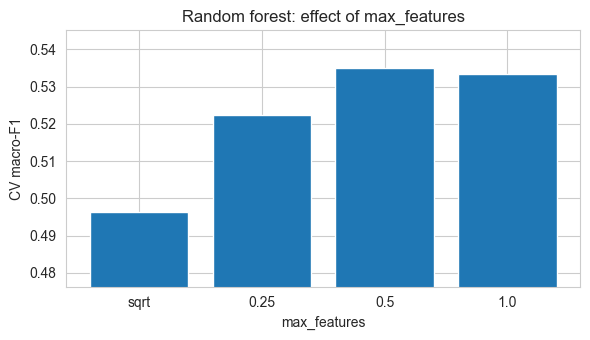

In [198]:
# small check of max_features (1.0 means every split sees all features, i.e. ordinary bagged trees)
if len(y_tr) > 40000:
    Xt_tune, _, y_tune, _ = train_test_split(Xt_train, y_tr, train_size=40000, stratify=y_tr, random_state=SEED)
else:
    Xt_tune, y_tune = Xt_train, y_tr

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
mf_scores = {}
mf_rows = []
for mf in ["sqrt", 0.25, 0.5, 1.0]:
    rf_try = RandomForestClassifier(n_estimators=50, criterion="entropy", max_depth=15, class_weight="balanced",
                                    max_features=mf, n_jobs=-1, random_state=SEED)
    scores = cross_val_score(rf_try, Xt_tune, y_tune, cv=cv, scoring="f1_macro")
    mf_scores[str(mf)] = scores.mean()
    mf_rows.append({"max_features": str(mf), "cv_macro_f1": scores.mean(), "cv_sd": scores.std()})
    print(f"max_features = {mf}: macro-F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")

pd.DataFrame(mf_rows).to_csv(f"results/{TAG}_max_features.csv", index=False)
best_mf = max(mf_scores, key=mf_scores.get)
best_mf = best_mf if best_mf == "sqrt" else float(best_mf)
print("Chosen max_features:", best_mf)

plt.figure(figsize=(6, 3.5))
plt.bar(list(mf_scores.keys()), list(mf_scores.values()))
plt.ylim(min(mf_scores.values()) - 0.02, max(mf_scores.values()) + 0.01)
plt.xlabel("max_features"); plt.ylabel("CV macro-F1"); plt.title("Random forest: effect of max_features")
plt.tight_layout(); plt.savefig(f"figures/{TAG}_rf_max_features.png", dpi=300, bbox_inches="tight"); plt.show()

In [199]:
rf_params = dict(n_estimators=N_TREES, criterion="entropy", max_depth=15, class_weight="balanced",
                 max_features=best_mf, n_jobs=-1, random_state=SEED)

t0 = time.time()
rf = RandomForestClassifier(**rf_params).fit(Xt_train, y_tr)
fit_s = time.time() - t0
t0 = time.time()
rf_preds = rf.predict(Xt_test)
evaluate("Random forest", rf_preds, fit_s, time.time() - t0)

Random forest: macro-F1 = 0.5898  (fit 65s, predict 0s)


## 6. Results

In [201]:
results_df = pd.DataFrame(rows).set_index("model")
results_df.to_csv(f"results/{TAG}_test_results.csv")
results_df.round(4)

,macro_f1,weighted_f1,accuracy,balanced_accuracy,detection_rate,false_alarm_rate,fit_seconds,predict_seconds
model,,,,,,,,
k-NN (A2),0.4687,0.7740,0.7801,0.4540,0.9264,0.0882,0.0771,299.2837
Decision tree (A2),0.5791,0.7857,0.7587,0.6676,0.9926,0.2459,6.0761,0.0284
Bagged trees,0.5946,0.7919,0.7685,0.6816,0.9947,0.2448,222.3189,6.0308
Bagged k-NN,0.4458,0.7650,0.7752,0.4331,0.9078,0.0748,0.6307,671.7858
Random forest,0.5898,0.7908,0.7668,0.6682,0.9955,0.2503,65.3684,0.4033


F1 per class


,k-NN (A2),Decision tree (A2),Bagged trees,Bagged k-NN,Random forest
Normal,0.893,0.853,0.856,0.886,0.853
Reconnaissance,0.680,0.827,0.835,0.669,0.839
Backdoor,0.025,0.107,0.116,0.036,0.088
DoS,0.335,0.478,0.487,0.338,0.480
Exploits,0.669,0.654,0.667,0.676,0.670
Analysis,0.187,0.142,0.160,0.057,0.145
Fuzzers,0.515,0.618,0.630,0.457,0.629
Worms,0.000,0.667,0.692,0.000,0.675
Shellcode,0.399,0.457,0.514,0.356,0.529
Generic,0.985,0.988,0.989,0.984,0.989


Recall per class


,k-NN (A2),Decision tree (A2),Bagged trees,Bagged k-NN,Random forest
Normal,0.912,0.754,0.755,0.925,0.750
Reconnaissance,0.648,0.812,0.830,0.635,0.830
Backdoor,0.015,0.305,0.266,0.026,0.178
DoS,0.345,0.666,0.709,0.348,0.697
Exploits,0.709,0.523,0.541,0.711,0.546
Analysis,0.107,0.207,0.200,0.030,0.213
Fuzzers,0.481,0.797,0.826,0.395,0.838
Worms,0.000,0.743,0.771,0.000,0.743
Shellcode,0.348,0.887,0.937,0.288,0.907
Generic,0.976,0.981,0.982,0.974,0.981


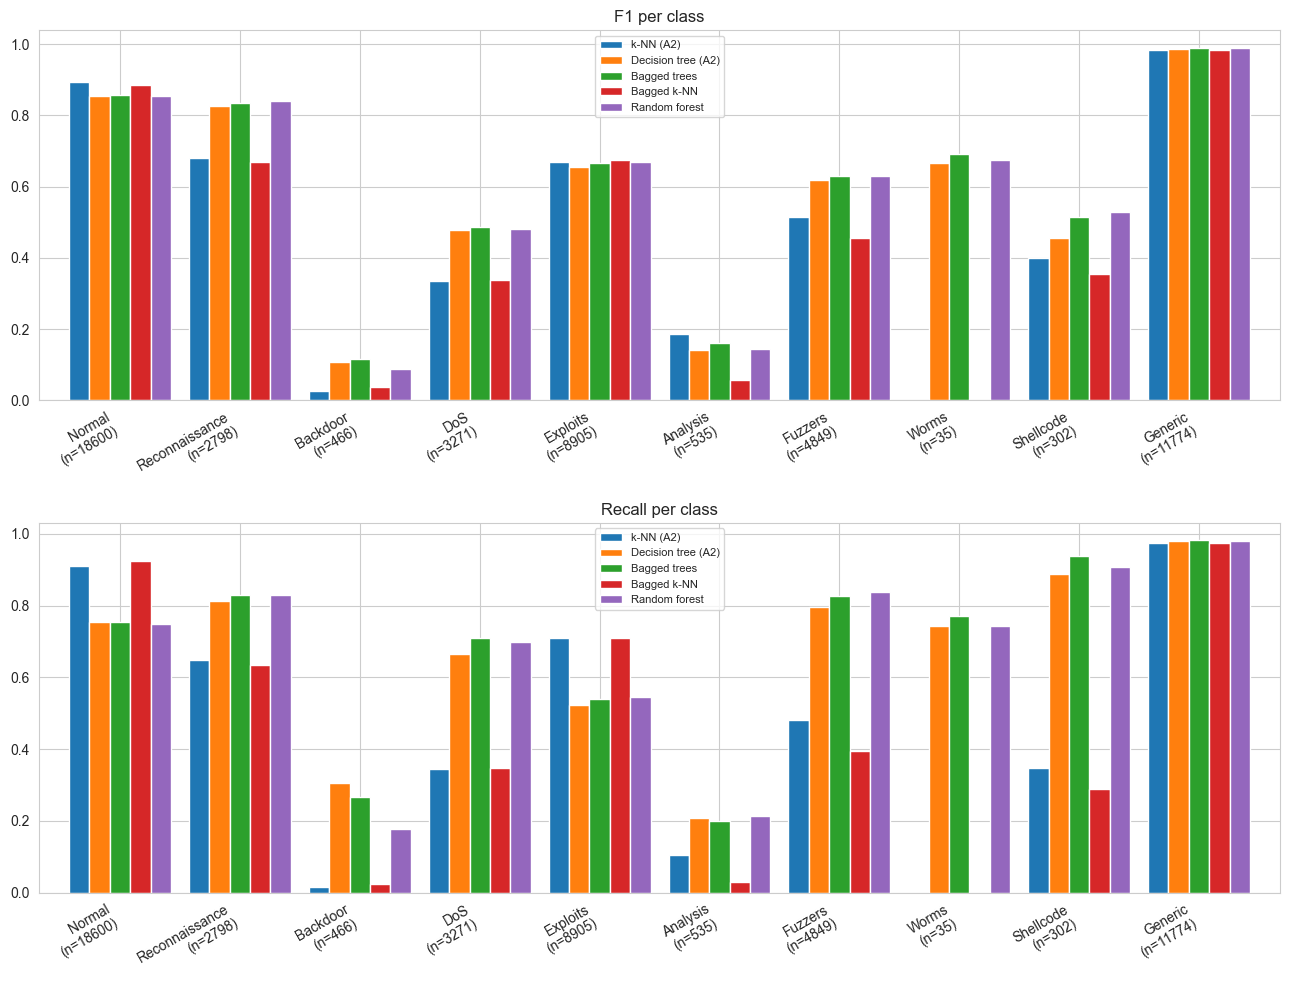

In [202]:
# Per-class F1 and recall (same style as the A2 plots)
labels = list(classes)
names = [class_mapping[i] for i in labels]
reports = {m: classification_report(y_te, p, output_dict=True, zero_division=0) for m, p in all_preds.items()}
support = [int(reports["k-NN (A2)"][str(c)]["support"]) for c in labels]

f1_table = pd.DataFrame({m: [r[str(c)]["f1-score"] for c in labels] for m, r in reports.items()}, index=names)
recall_table = pd.DataFrame({m: [r[str(c)]["recall"] for c in labels] for m, r in reports.items()}, index=names)
f1_table.to_csv(f"results/{TAG}_per_class_f1.csv", index_label="class"); recall_table.to_csv(f"results/{TAG}_per_class_recall.csv", index_label="class")
print("F1 per class"); display(f1_table.round(3))
print("Recall per class"); display(recall_table.round(3))

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, table, title in [(axes[0], f1_table, "F1 per class"), (axes[1], recall_table, "Recall per class")]:
    table.plot.bar(ax=ax, width=0.85)
    ax.set_title(title)
    ax.set_xticklabels([f"{n}\n(n={s})" for n, s in zip(names, support)], rotation=30, ha="right")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"figures/{TAG}_per_class_comparison.png", dpi=300, bbox_inches="tight"); plt.show()

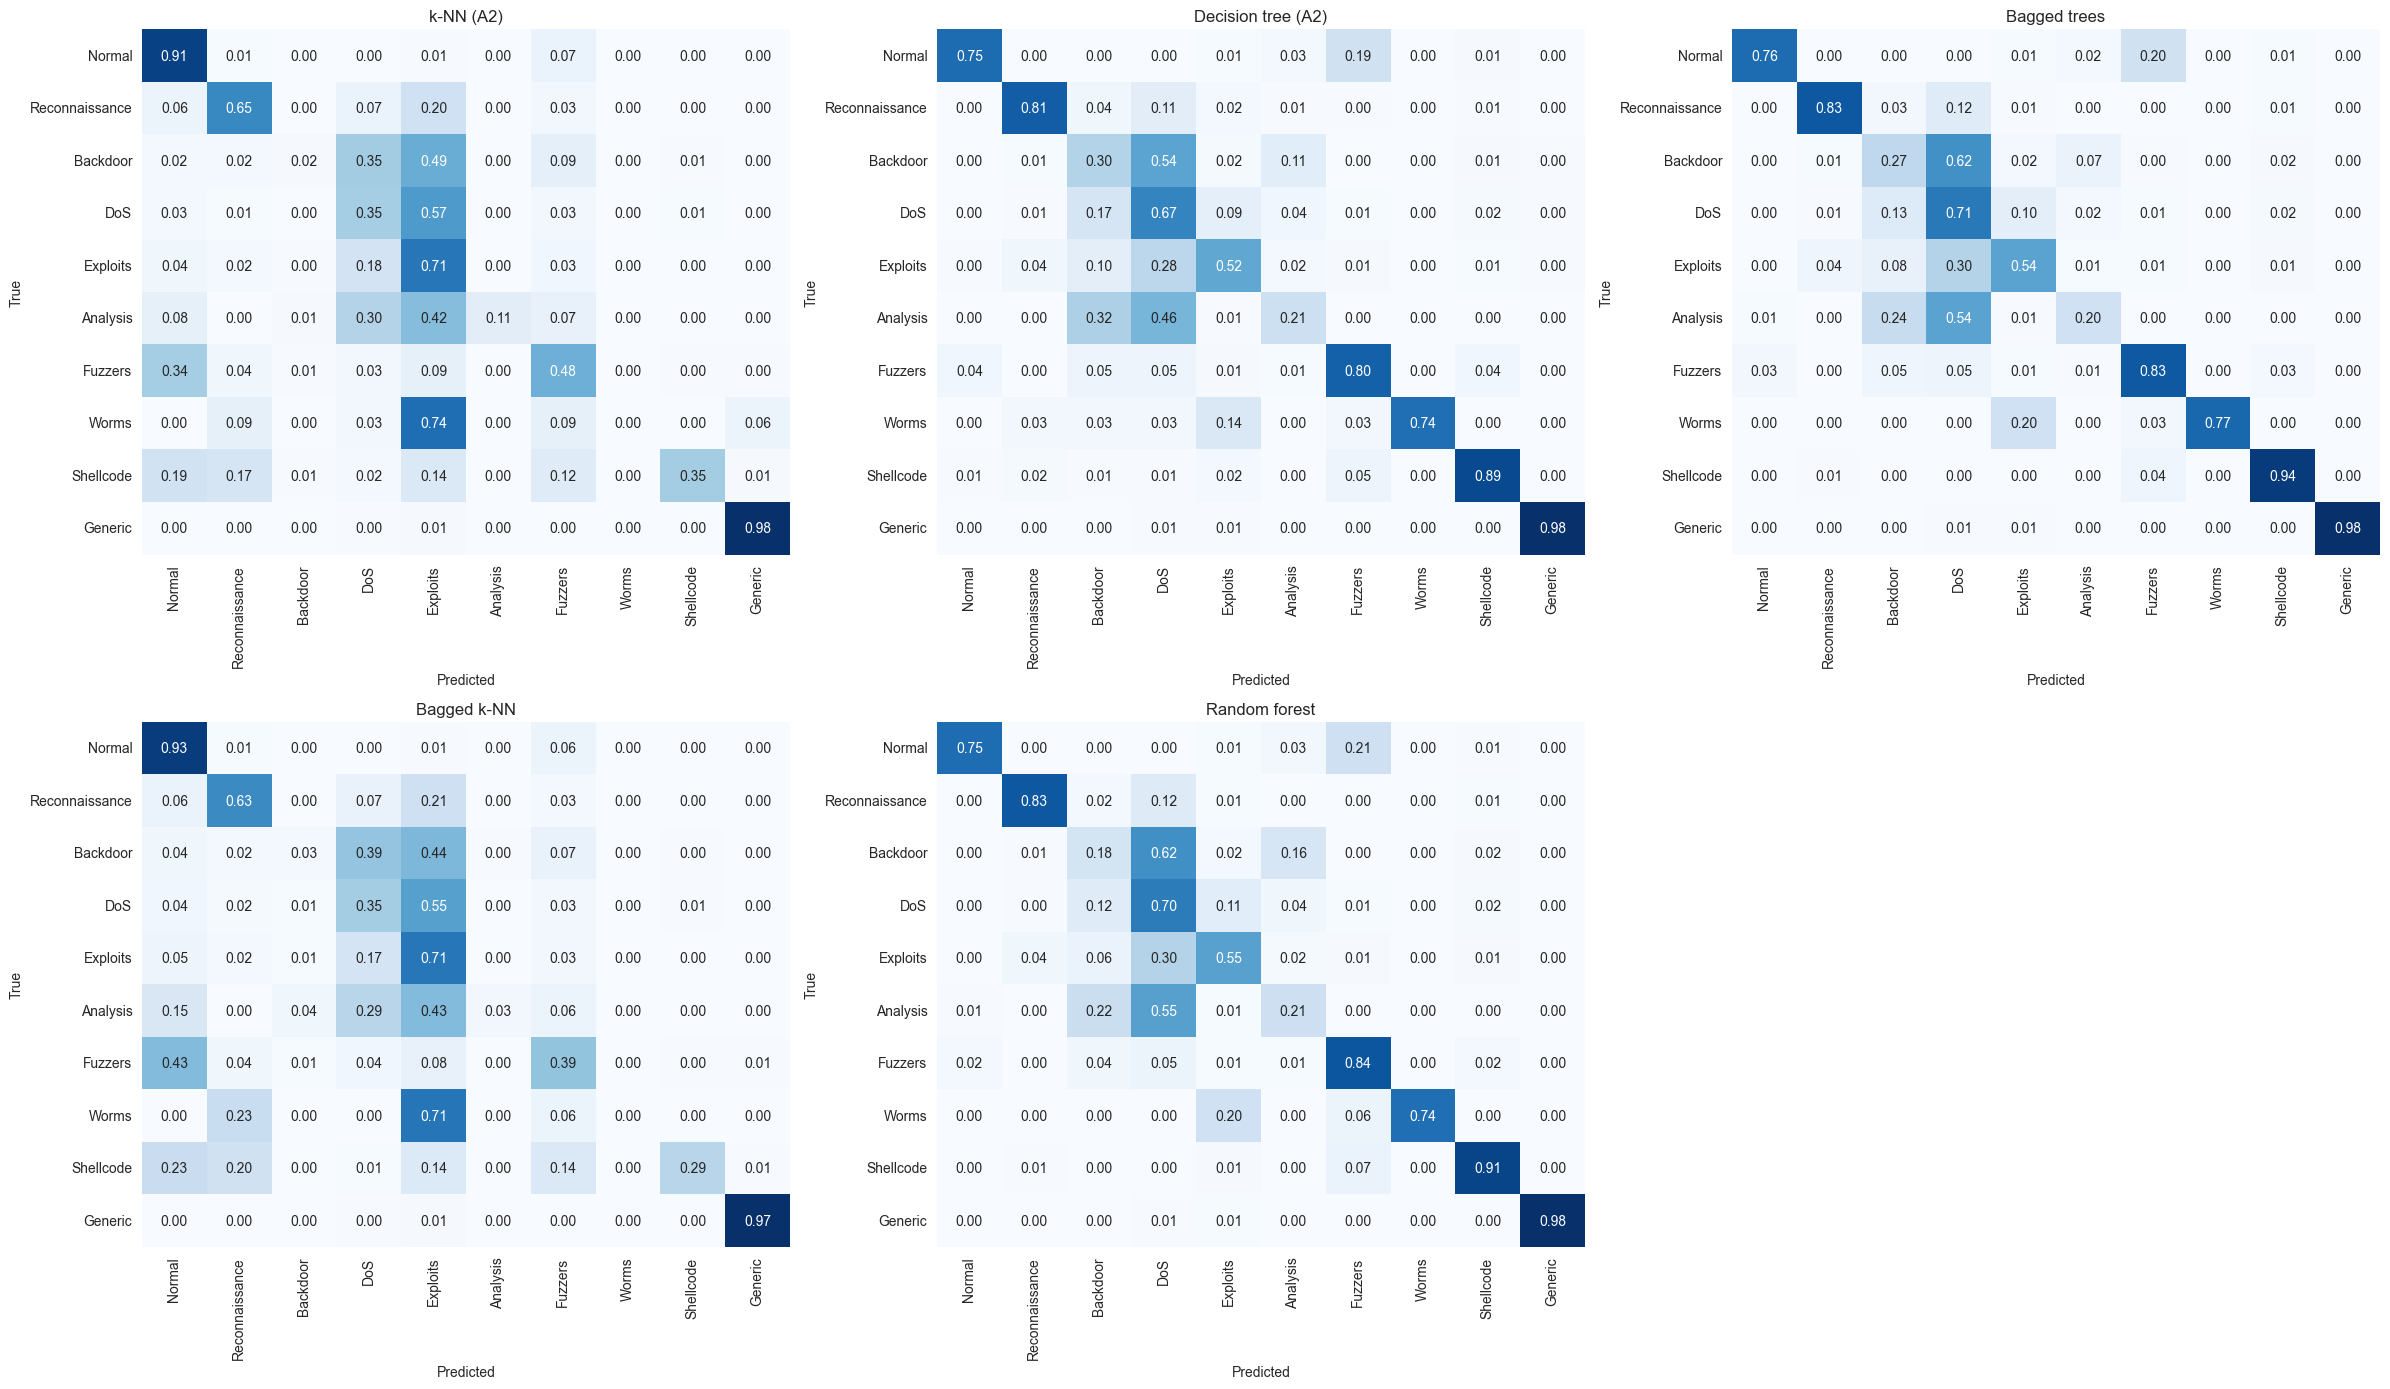

In [203]:
# Confusion matrices (row-normalised: each row shows where the rows of one true class ended up)
fig, axes = plt.subplots(2, 3, figsize=(24, 14))
for ax, (m, p) in zip(axes.flat, all_preds.items()):
    cm = confusion_matrix(y_te, p, labels=labels)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(m); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for ax in list(axes.flat)[len(all_preds):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"figures/{TAG}_confusion_matrices.png", dpi=300, bbox_inches="tight"); plt.show()

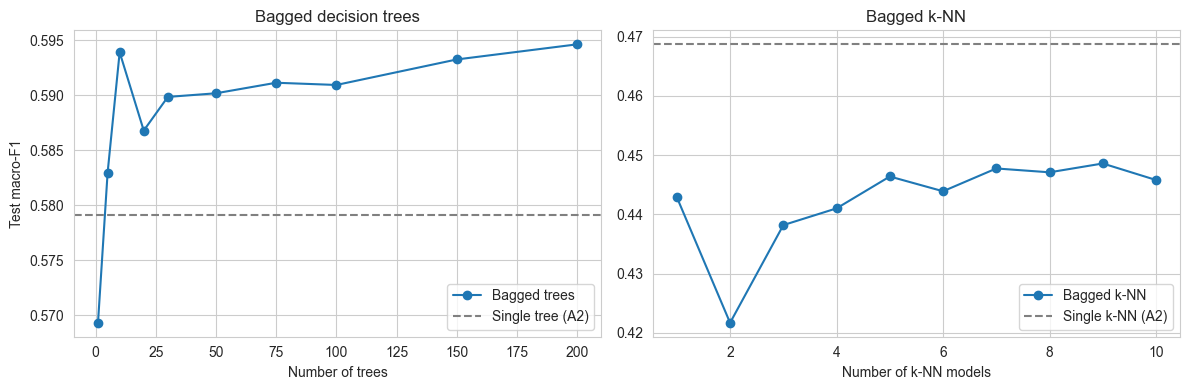

In [247]:
# How does macro-F1 change as more models are added to the bag? (descriptive only: the number of models was fixed beforehand)
def curve(votes, ks):
    return [f1_score(y_te, majority_vote(votes[:k]), average="macro") for k in ks]

tree_ks = [k for k in [1, 5, 10, 20, 30, 50, 75, 100, 150, 200] if k <= N_TREES]
knn_ks = list(range(1, N_KNN_BAGS + 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tree_ks, curve(bag_tree_votes, tree_ks), "o-", label="Bagged trees")
axes[0].axhline(f1_score(y_te, tree_preds, average="macro"), color="grey", linestyle="--", label="Single tree (A2)")
axes[0].set_title("Bagged decision trees"); axes[0].set_xlabel("Number of trees"); axes[0].set_ylabel("Test macro-F1"); axes[0].legend()

axes[1].plot(knn_ks, curve(bag_knn_votes, knn_ks), "o-", label="Bagged k-NN")
axes[1].axhline(f1_score(y_te, knn_preds, average="macro"), color="grey", linestyle="--", label="Single k-NN (A2)")
axes[1].set_title("Bagged k-NN"); axes[1].set_xlabel("Number of k-NN models"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"figures/{TAG}_models_vs_f1.png", dpi=300, bbox_inches="tight"); plt.show()

In [205]:
# Are the differences real? Bootstrap the test set and look at the difference in macro-F1 (same rows for both models).
def bootstrap_diff(preds_a, preds_b, n_boot=300):
    rng = np.random.default_rng(SEED)
    n = len(y_te)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        diffs.append(f1_score(y_te[i], preds_a[i], average="macro") - f1_score(y_te[i], preds_b[i], average="macro"))
    return np.mean(diffs), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

pairs = [("Bagged trees", "Decision tree (A2)"), ("Random forest", "Decision tree (A2)"),
         ("Random forest", "Bagged trees"), ("Bagged k-NN", "k-NN (A2)"),
         ("Random forest", "k-NN (A2)")]
diff_rows = []
for a, b in pairs:
    mean_d, lo, hi = bootstrap_diff(all_preds[a], all_preds[b])
    diff_rows.append({"model A": a, "model B": b, "macro-F1 difference (A - B)": mean_d,
                      "95% CI low": lo, "95% CI high": hi, "CI excludes 0": (lo > 0) or (hi < 0)})
diff_df = pd.DataFrame(diff_rows)
diff_df.to_csv(f"results/{TAG}_bootstrap_differences.csv", index=False)
diff_df.round(4)

,model A,model B,macro-F1 difference (A - B),95% CI low,95% CI high,CI excludes 0
0,Bagged trees,Decision tree (A2),0.0154,0.0069,0.0248,True
1,Random forest,Decision tree (A2),0.0108,0.0023,0.0191,True
2,Random forest,Bagged trees,-0.0046,-0.0117,0.0024,False
3,Bagged k-NN,k-NN (A2),-0.0228,-0.0294,-0.0164,True
4,Random forest,k-NN (A2),0.1205,0.1054,0.1335,True


## 7. Quick try: class re-weighting

The tree-based models were trained with balanced class weights, which pushes them to predict rare attack classes more often (and flag a lot of normal traffic). Re-weighting is a simple fix at prediction time:

* the forest gives a probability for each class,
* each class probability is multiplied by a weight, and the class with the largest weighted probability is predicted,
* the weights are chosen to maximise macro-F1 on a **validation set taken from the training data** (never the test set).

For this, the forest is refitted on 80% of the training data and the other 20% is the validation set. The comparison is then the **same forest** with and without the weights.

In [207]:
# validation split from the training data
X_fit, X_val, y_fit, y_val = train_test_split(Xt_train, y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)

rf_rw = RandomForestClassifier(**rf_params).fit(X_fit, y_fit)
p_val = rf_rw.predict_proba(X_val)
p_test = rf_rw.predict_proba(Xt_test)
rw_classes = rf_rw.classes_

def val_score(w):
    return f1_score(y_val, rw_classes[(p_val * w).argmax(axis=1)], average="macro")

# try changing one class weight at a time and keep the change if validation macro-F1 improves
weights = np.ones(len(rw_classes))
best = val_score(weights)
val_before = best
print("Validation macro-F1 before:", round(best, 4))
for sweep in range(2):
    for c in range(len(rw_classes)):
        for factor in [0.25, 0.5, 0.75, 1.5, 2, 3, 4]:
            trial = weights.copy()
            trial[c] *= factor
            s = val_score(trial)
            if s > best:
                best, weights = s, trial
print("Validation macro-F1 after: ", round(best, 4))
learned = pd.Series(weights, index=[class_mapping[c] for c in rw_classes]).rename("learned weight")
learned.to_csv(f"results/{TAG}_reweighting_weights.csv", index_label="class")
print(learned.round(2))

Validation macro-F1 before: 0.5906
Validation macro-F1 after:  0.6273
Normal            1.50
Reconnaissance    0.75
Backdoor          0.56
DoS               1.50
Exploits          1.00
Analysis          1.00
Fuzzers           0.75
Worms             2.00
Shellcode         0.25
Generic           1.00
Name: learned weight, dtype: float64


,macro_f1,balanced_accuracy,accuracy,detection_rate,false_alarm_rate
"Forest (80% of training), no weights",0.5911,0.6637,0.7665,0.9954,0.2482
"Same forest, re-weighted",0.6182,0.6488,0.8081,0.9667,0.1126


Change in test macro-F1: +0.0272  (95% bootstrap interval +0.0199 to +0.0355)


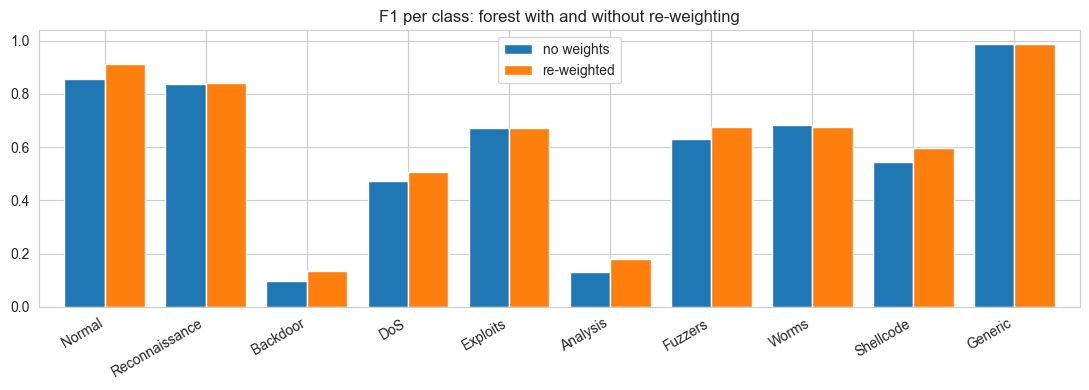

In [208]:
preds_before = rw_classes[p_test.argmax(axis=1)]
preds_after = rw_classes[(p_test * weights).argmax(axis=1)]

attack = y_te != 0
def summary(preds):
    flagged = preds != 0
    return {"macro_f1": f1_score(y_te, preds, average="macro"),
            "balanced_accuracy": balanced_accuracy_score(y_te, preds),
            "accuracy": accuracy_score(y_te, preds),
            "detection_rate": flagged[attack].mean(),
            "false_alarm_rate": flagged[~attack].mean()}

rw_table = pd.DataFrame({"Forest (80% of training), no weights": summary(preds_before),
                         "Same forest, re-weighted": summary(preds_after)}).T
rw_table.to_csv(f"results/{TAG}_reweighting.csv", index_label="version")
display(rw_table.round(4))

mean_d, lo, hi = bootstrap_diff(preds_after, preds_before)
print(f"Change in test macro-F1: {mean_d:+.4f}  (95% bootstrap interval {lo:+.4f} to {hi:+.4f})")
pd.DataFrame([{"change_in_test_macro_f1": mean_d, "ci_low": lo, "ci_high": hi, "validation_before": val_before, "validation_after": best}]).to_csv(f"results/{TAG}_reweighting_change.csv", index=False)

f1_before = classification_report(y_te, preds_before, output_dict=True, zero_division=0)
f1_after = classification_report(y_te, preds_after, output_dict=True, zero_division=0)
rw_f1 = pd.DataFrame({"no weights": [f1_before[str(c)]["f1-score"] for c in labels],
                      "re-weighted": [f1_after[str(c)]["f1-score"] for c in labels]}, index=names)
rw_f1.plot.bar(figsize=(11, 4), width=0.8)
plt.title("F1 per class: forest with and without re-weighting"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(f"figures/{TAG}_reweighting_f1.png", dpi=300, bbox_inches="tight"); plt.show()

## 8. Diagnostics (check how far the results can be trusted)

Three short checks. None of them changes the models; they show how much weight the comparisons above can carry.

In [210]:
# 8.1 Duplicates and train/test overlap. Many rows in this dataset are exact copies of each other, so a model can score well
# by remembering training rows, and the test rows are not fully independent of the training rows.
h_train = pd.util.hash_pandas_object(X_train, index=False)
h_test = pd.util.hash_pandas_object(X_test, index=False)
print(f"Duplicate rows inside the training features: {h_train.duplicated().mean():.1%}")

seen = h_test.isin(set(h_train.values)).values        # test rows whose exact feature values also appear in the training data
print(f"Test rows with an identical feature row in the training data: {seen.mean():.1%}")
dup_stats = {"duplicate_train_rows": h_train.duplicated().mean(), "test_rows_with_twin_in_train": seen.mean()}

pd.DataFrame([dup_stats]).to_csv(f"results/{TAG}_duplicates.csv", index=False)   # (re-saved below with the label match when there are twins)
if seen.any() and (~seen).any():
    train_label = pd.Series(y_tr, index=h_train.values)
    train_label = train_label[~train_label.index.duplicated()]        # label of the first matching training row
    same_label = (train_label.reindex(h_test[seen].values).values == y_te[seen]).mean()
    print(f"...and of those, the label matches the training copy in {same_label:.1%} of cases")
    dup_stats["twin_label_matches"] = same_label
    pd.DataFrame([dup_stats]).to_csv(f"results/{TAG}_duplicates.csv", index=False)

    table = []
    for name, p in all_preds.items():
        table.append({"model": name,
                      "macro-F1 (seen rows)": f1_score(y_te[seen], p[seen], average="macro"),
                      "macro-F1 (unseen rows)": f1_score(y_te[~seen], p[~seen], average="macro"),
                      "accuracy (seen rows)": accuracy_score(y_te[seen], p[seen]),
                      "accuracy (unseen rows)": accuracy_score(y_te[~seen], p[~seen])})
    seen_table = pd.DataFrame(table).set_index("model")
    seen_table.to_csv(f"results/{TAG}_seen_vs_unseen.csv")
    display(seen_table.round(4))

Duplicate rows inside the training features: 39.0%
Test rows with an identical feature row in the training data: 45.1%
...and of those, the label matches the training copy in 76.1% of cases


,macro-F1 (seen rows),macro-F1 (unseen rows),accuracy (seen rows),accuracy (unseen rows)
model,,,,
k-NN (A2),0.5302,0.4360,0.7753,0.7841
Decision tree (A2),0.5446,0.6241,0.7315,0.7810
Bagged trees,0.5387,0.6567,0.7386,0.7930
Bagged k-NN,0.4863,0.4069,0.7655,0.7833
Random forest,0.5461,0.6626,0.7338,0.7938


In [211]:
# 8.2 Control for the bagged k-NN. Each bag only sees KNN_BAG_FRAC of the data, so compare it with a SINGLE k-NN trained
# on that same amount of data. This separates "bagging" from "using less data".
idx = np.random.default_rng(SEED).choice(len(y_tr), int(KNN_BAG_FRAC * len(y_tr)), replace=False)
t0 = time.time()
knn_small = KNeighborsClassifier(**KNN_PARAMS).fit(Xk_train[idx], y_tr[idx])
preds_small = knn_small.predict(Xk_test)
print(f"Single k-NN on {KNN_BAG_FRAC:.0%} of the training data: macro-F1 = {f1_score(y_te, preds_small, average='macro'):.4f} ({time.time() - t0:.0f}s)")
print(f"Bagged k-NN ({N_KNN_BAGS} bags of that size):        macro-F1 = {f1_score(y_te, all_preds['Bagged k-NN'], average='macro'):.4f}")
print(f"Single k-NN on all the training data:             macro-F1 = {f1_score(y_te, all_preds['k-NN (A2)'], average='macro'):.4f}")
d, lo, hi = bootstrap_diff(all_preds["Bagged k-NN"], preds_small)
print(f"Bagging effect (bagged minus single k-NN of the same size): {d:+.4f}  (95% interval {lo:+.4f} to {hi:+.4f})")
pd.DataFrame([{"single_knn_30pct": f1_score(y_te, preds_small, average="macro"),
               "bagged_knn": f1_score(y_te, all_preds["Bagged k-NN"], average="macro"),
               "single_knn_all_data": f1_score(y_te, all_preds["k-NN (A2)"], average="macro"),
               "bagging_effect": d, "ci_low": lo, "ci_high": hi}]).to_csv(f"results/{TAG}_knn_control.csv", index=False)

Single k-NN on 30% of the training data: macro-F1 = 0.4491 (67s)
Bagged k-NN (10 bags of that size):        macro-F1 = 0.4458
Single k-NN on all the training data:             macro-F1 = 0.4687
Bagging effect (bagged minus single k-NN of the same size): -0.0034  (95% interval -0.0179 to +0.0061)


In [212]:
# 8.3 Variation caused by the training data. Refit on different random halves of the training data and see how much the
# test macro-F1 moves for each model (k-NN is left out because it is slow).
n_rep = 5
scores = {"Decision tree": [], "Bagged trees (25 trees)": [], "Random forest (25 trees)": []}
for r in range(n_rep):
    idx = np.random.default_rng(100 + r).choice(len(y_tr), len(y_tr) // 2, replace=False)
    Xs, ys = Xt_train[idx], y_tr[idx]

    t = DecisionTreeClassifier(random_state=SEED, **TREE_PARAMS).fit(Xs, ys)
    scores["Decision tree"].append(f1_score(y_te, t.predict(Xt_test), average="macro"))

    bag = bagging_fit(lambda: DecisionTreeClassifier(random_state=SEED, **TREE_PARAMS), Xs, ys, n_models=25, n_jobs=-1)
    scores["Bagged trees (25 trees)"].append(f1_score(y_te, majority_vote(get_votes(bag, Xt_test)), average="macro"))

    rf_s = RandomForestClassifier(**{**rf_params, "n_estimators": 25}).fit(Xs, ys)
    scores["Random forest (25 trees)"].append(f1_score(y_te, rf_s.predict(Xt_test), average="macro"))
    print("repeat", r + 1, "done")

variation = pd.DataFrame(scores).agg(["mean", "std"]).T
variation.to_csv(f"results/{TAG}_training_variation.csv", index_label="model")
variation.round(4)

repeat 1 done
repeat 2 done
repeat 3 done
repeat 4 done
repeat 5 done


,mean,std
Decision tree,0.5497,0.0075
Bagged trees (25 trees),0.5725,0.0043
Random forest (25 trees),0.5767,0.0037


## 9. Average over the two seeds

Run this cell after the notebook has been run once with `SEED = 1` and once with `SEED = 2`. It reads the saved files for each seed and reports the **mean** and **standard deviation** across seeds. With only two seeds the standard deviation is a rough guide, so report the per-seed values as well.

Each seed changes the stratified train/test split and all the random choices (bootstrap samples, forest, cross-validation folds, validation split), so even the k-NN and decision tree baselines vary between seeds.

In [214]:
def load_seeds(name):
    tables = {}
    for s in SEEDS_TO_AVERAGE:
        path = f"results/seed{s}_{name}.csv"
        if os.path.exists(path):
            tables[s] = pd.read_csv(path)
    return tables

def average_over_seeds(name, key):
    tables = load_seeds(name)
    if not tables:
        raise FileNotFoundError(f"No saved results found for '{name}'. Run the notebook for each seed first.")
    stacked = pd.concat([t.assign(seed=s) for s, t in tables.items()], ignore_index=True)
    values = stacked.drop(columns=[c for c in stacked.columns if stacked[c].dtype == bool])
    grouped = values.drop(columns="seed").groupby(key, sort=False)
    return grouped.mean(numeric_only=True), grouped.std(numeric_only=True), stacked, sorted(tables)

mean, sd, stacked, seeds_found = average_over_seeds("test_results", "model")
print("Seeds found:", seeds_found)
print("MEAN across seeds"); display(mean.round(4))
print("STANDARD DEVIATION across seeds"); display(sd.round(4))
print("Macro-F1 for each seed"); display(stacked.pivot(index="model", columns="seed", values="macro_f1").loc[mean.index].round(4))
mean.to_csv("results/averaged_test_results.csv"); sd.to_csv("results/averaged_test_results_sd.csv")

Seeds found: [19, 27]
MEAN across seeds


,macro_f1,weighted_f1,accuracy,balanced_accuracy,detection_rate,false_alarm_rate,fit_seconds,predict_seconds
model,,,,,,,,
k-NN (A2),0.4796,0.7748,0.7816,0.4607,0.9253,0.0857,0.0888,427.9408
Decision tree (A2),0.5741,0.7852,0.7555,0.6630,0.9919,0.2374,9.7528,0.0397
Bagged trees,0.5946,0.7929,0.7695,0.6806,0.9948,0.2405,252.1165,8.4025
Bagged k-NN,0.4467,0.7643,0.7748,0.4333,0.9063,0.0723,0.7286,869.6378
Random forest,0.5907,0.7927,0.7690,0.6652,0.9956,0.2439,71.4937,0.4029


STANDARD DEVIATION across seeds


,macro_f1,weighted_f1,accuracy,balanced_accuracy,detection_rate,false_alarm_rate,fit_seconds,predict_seconds
model,,,,,,,,
k-NN (A2),0.0154,0.0011,0.0020,0.0095,0.0015,0.0036,0.0165,181.9486
Decision tree (A2),0.0072,0.0008,0.0045,0.0065,0.0011,0.0121,5.1997,0.0160
Bagged trees,0.0000,0.0014,0.0014,0.0014,0.0002,0.0061,42.1402,3.3541
Bagged k-NN,0.0013,0.0010,0.0007,0.0003,0.0022,0.0036,0.1385,279.8050
Random forest,0.0012,0.0027,0.0031,0.0043,0.0001,0.0090,8.6624,0.0006


Macro-F1 for each seed


seed,19,27
model,,
k-NN (A2),0.4904,0.4687
Decision tree (A2),0.5690,0.5791
Bagged trees,0.5946,0.5946
Bagged k-NN,0.4476,0.4458
Random forest,0.5916,0.5898


Mean F1 per class


,k-NN (A2),Decision tree (A2),Bagged trees,Bagged k-NN,Random forest
class,,,,,
Normal,0.893,0.858,0.859,0.886,0.857
Reconnaissance,0.684,0.825,0.831,0.670,0.834
Backdoor,0.016,0.104,0.114,0.029,0.086
DoS,0.332,0.439,0.482,0.334,0.477
Exploits,0.671,0.653,0.668,0.671,0.672
Analysis,0.191,0.133,0.160,0.057,0.144
Fuzzers,0.516,0.625,0.632,0.459,0.634
Worms,0.095,0.638,0.684,0.000,0.676
Shellcode,0.413,0.479,0.527,0.377,0.538


Mean recall per class


,k-NN (A2),Decision tree (A2),Bagged trees,Bagged k-NN,Random forest
class,,,,,
Normal,0.914,0.763,0.759,0.928,0.756
Reconnaissance,0.652,0.816,0.830,0.637,0.828
Backdoor,0.010,0.342,0.260,0.020,0.167
DoS,0.337,0.560,0.697,0.347,0.691
Exploits,0.714,0.520,0.541,0.704,0.548
Analysis,0.109,0.239,0.207,0.030,0.220
Fuzzers,0.481,0.798,0.826,0.391,0.838
Worms,0.057,0.729,0.771,0.000,0.714
Shellcode,0.358,0.882,0.932,0.301,0.909


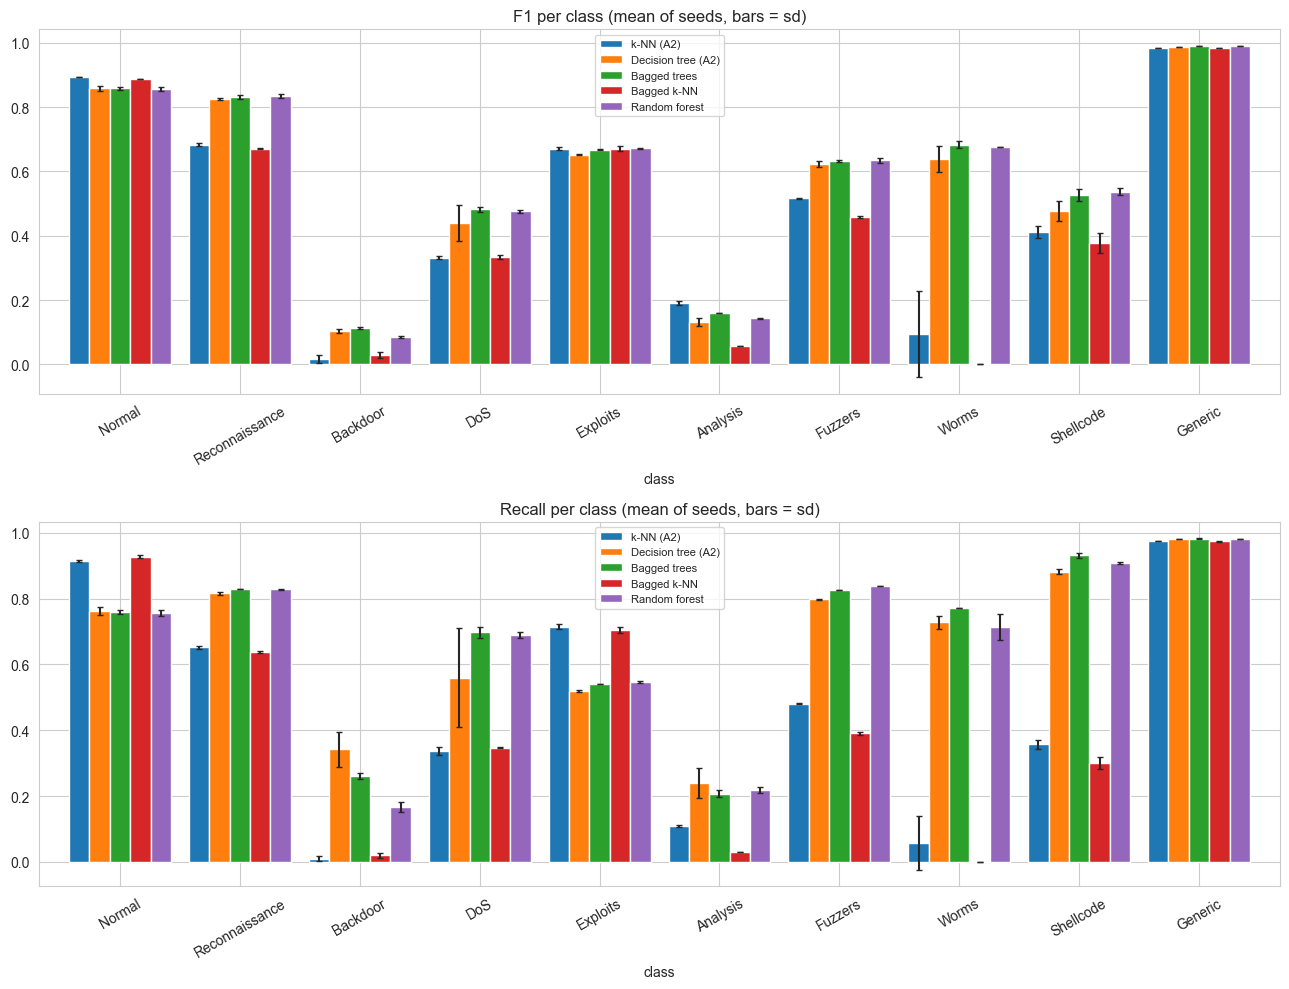

In [215]:
# Per-class F1 and recall: mean with standard-deviation error bars
f1_mean, f1_sd, _, _ = average_over_seeds("per_class_f1", "class")
rec_mean, rec_sd, _, _ = average_over_seeds("per_class_recall", "class")
print("Mean F1 per class"); display(f1_mean.round(3))
print("Mean recall per class"); display(rec_mean.round(3))

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, m, s_, title in [(axes[0], f1_mean, f1_sd, "F1 per class (mean of seeds, bars = sd)"),
                         (axes[1], rec_mean, rec_sd, "Recall per class (mean of seeds, bars = sd)")]:
    m.plot.bar(ax=ax, yerr=s_, width=0.85, capsize=2)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/averaged_per_class.png", dpi=300, bbox_inches="tight"); plt.show()

In [216]:
# Paired bootstrap differences: one column per seed (the mean is the average of the seeds' differences)
tables = load_seeds("bootstrap_differences")
diff_all = pd.concat([t.assign(seed=s) for s, t in tables.items()], ignore_index=True)
diff_all["pair"] = diff_all["model A"] + " vs " + diff_all["model B"]
col = "macro-F1 difference (A - B)"
summary = diff_all.pivot(index="pair", columns="seed", values=col)
summary.columns = [f"diff seed {c}" for c in summary.columns]
summary["mean diff"] = summary.mean(axis=1)
excl = diff_all.pivot(index="pair", columns="seed", values="CI excludes 0")
summary["95% CI excludes 0 in every seed"] = excl.all(axis=1)
summary = summary.loc[diff_all["pair"].drop_duplicates()]
summary.to_csv("results/averaged_bootstrap_differences.csv")
summary.round(4)

,diff seed 19,diff seed 27,mean diff,95% CI excludes 0 in every seed
pair,,,,
Bagged trees vs Decision tree (A2),0.0259,0.0154,0.0207,True
Random forest vs Decision tree (A2),0.0231,0.0108,0.0170,True
Random forest vs Bagged trees,-0.0027,-0.0046,-0.0037,False
Bagged k-NN vs k-NN (A2),-0.0429,-0.0228,-0.0329,True
Random forest vs k-NN (A2),0.1008,0.1205,0.1106,True


In [217]:
# Re-weighting, random-forest max_features, and the diagnostics
rw_mean, rw_sd, rw_stacked, _ = average_over_seeds("reweighting", "version")
print("Re-weighting: mean across seeds"); display(rw_mean.round(4))
print("Re-weighting: sd across seeds"); display(rw_sd.round(4))
print("Change in test macro-F1 and validation gain, per seed"); display(pd.concat([t.assign(seed=s) for s, t in load_seeds("reweighting_change").items()]).round(4))
print("Learned multipliers, per seed"); display(pd.concat({s: t.set_index("class")["learned weight"] for s, t in load_seeds("reweighting_weights").items()}, axis=1).round(2))

mf_mean, mf_sd, _, _ = average_over_seeds("max_features", "max_features")
print("max_features (CV macro-F1 averaged over seeds)"); display(mf_mean.round(4))

print("Duplicates, per seed"); display(pd.concat([t.assign(seed=s) for s, t in load_seeds("duplicates").items()]).round(4))
su_mean, su_sd, _, _ = average_over_seeds("seen_vs_unseen", "model")
print("Seen vs unseen rows: mean across seeds"); display(su_mean.round(4))
print("Seen vs unseen rows: sd across seeds"); display(su_sd.round(4))
print("k-NN size control, per seed"); display(pd.concat([t.assign(seed=s) for s, t in load_seeds("knn_control").items()]).round(4))
var_mean, var_sd, _, _ = average_over_seeds("training_variation", "model")
print("Variation across random halves of the training data (mean over seeds of each seed's mean)"); display(var_mean.round(4))

Re-weighting: mean across seeds


,macro_f1,balanced_accuracy,accuracy,detection_rate,false_alarm_rate
version,,,,,
"Forest (80% of training), no weights",0.5861,0.6546,0.7678,0.9951,0.2402
"Same forest, re-weighted",0.6182,0.6421,0.8113,0.9681,0.1104


Re-weighting: sd across seeds


,macro_f1,balanced_accuracy,accuracy,detection_rate,false_alarm_rate
version,,,,,
"Forest (80% of training), no weights",0.0071,0.0128,0.0017,0.0003,0.0113
"Same forest, re-weighted",0.0001,0.0095,0.0046,0.0020,0.0032


Change in test macro-F1 and validation gain, per seed


...

,macro-F1 (seen rows),macro-F1 (unseen rows),accuracy (seen rows),accuracy (unseen rows)
model,,,,
k-NN (A2),0.0052,0.0085,0.0018,0.0022
Decision tree (A2),0.0364,0.0105,0.0165,0.0054
Bagged trees,0.0244,0.0064,0.0005,0.0030
Bagged k-NN,0.0394,0.0061,0.0019,0.0004
Random forest,0.0344,0.0066,0.0019,0.0041


k-NN size control, per seed


,single_knn_30pct,bagged_knn,single_knn_all_data,bagging_effect,ci_low,ci_high,seed
0,0.4626,0.4476,0.4904,-0.0151,-0.0331,-0.0003,19
0,0.4491,0.4458,0.4687,-0.0034,-0.0179,0.0061,27


Variation across random halves of the training data (mean over seeds of each seed's mean)


,mean,std
model,,
Decision tree,0.5558,0.0080
Bagged trees (25 trees),0.5757,0.0054
Random forest (25 trees),0.5760,0.0036


### Where to look when writing up

* **Section 6 table**: the main comparison of all five models (macro-F1, balanced accuracy, detection and false-alarm rates, run times).
* **Per-class plots and confusion matrices**: which attack families improve or get worse, and what is still confused with what.
* **Models-vs-F1 plot**: does adding more models keep helping? Compare the trees with k-NN.
* **Bootstrap table**: whether a difference in macro-F1 is bigger than the noise from the finite test set.
* **Section 7**: what re-weighting changes (macro-F1 and the trade-off between detection and false alarms).
* **Section 9**: the averages and standard deviations over the two seeds (use these as the main results).
* **Section 8**: duplicates and train/test overlap, the fair control for the bagged k-NN, and how much each model varies with the training data.

Remember when describing the method: the bagged k-NN uses only a fraction of the data per bag, the random forest's `max_features` was chosen by 3-fold CV on a 40,000-row training subsample, and the re-weighting weights were chosen on a validation set cut from the training data.